# Real Estate Data Analysis Project

This notebook analyzes real estate data from multiple sources, performs data cleaning and preprocessing, conducts exploratory data analysis, builds predictive models, and implements a property recommendation system.

## Table of Contents
1. Data Loading & Initial Setup
2. Data Cleaning & Preprocessing
3. Data Merging
4. Exploratory Data Analysis (EDA)
5. Modeling
6. Property Recommendation System

# 1. Data Loading and Initial Setup
Loading necessary libraries and datasets for the real estate analysis project.

## 1.2 Load Datasets

In [67]:
# 1. Setup and Data Loading
## 1.1 Import Required Libraries

import pandas as pd
import seaborn as sns
from scipy import stats
from scipy.stats import skew
from scipy.special import boxcox1p
from scipy.stats import boxcox_normmax
# Machine learning models imports
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
# Data pre-processing
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
# Pre-processing
from sklearn import preprocessing
import numpy as np

df1 = pd.read_csv('/content/Egypt_Houses_Price_cleaned_data.csv')
df2 = pd.read_csv('/content/real_estate_data_bayut_full_cleaned_data.csv')
df3 = pd.read_csv('/content/properties_cleaned_data.csv')

df1.columns = df1.columns.str.lower()
df2.columns = df2.columns.str.lower()
df3.columns = df3.columns.str.lower()

# 2. Data Cleaning and Preprocessing
## 2.1 Property Type Standardization

In [68]:
# 1. Data Loading and Initial Setup
df1.rename(columns={'city': 'location'}, inplace=True)

In [69]:

df1["type"].value_counts()

,count
type,
Apartment,8499
Chalet,6589
Stand Alone Villa,4059
Town House,3067
Twin House,1788
Duplex,860
Standalone Villa,574
Penthouse,526
Twin house,483


In [70]:
df2["type"].value_counts()

,count
type,
Apartment,27601
Villa,7744
Chalet,4999
Townhouse,3241
Duplex,1985
Twin House,1673
Penthouse,1288
iVilla,324
Hotel Apartment,153


In [71]:
df3["type"].value_counts()

,count
type,
apartment,5650
villa,2710
townhouse,830
twin house,587
duplex,552
penthouse,434
ivilla,196
hotel apartment,30
chalet,14


In [72]:
def standardize_property_types(df):
    # First convert all to lowercase and strip whitespace
    df['type'] = df['type'].str.lower().str.strip()

    # Create comprehensive mapping dictionary for property types
    type_mapping = {
        # Apartment variations
        'apartment': 'Apartment',
        'apartement': 'Apartment',
        'flat': 'Apartment',
        'hotel apartment': 'Apartment',
        'hotel_apartment': 'Apartment',

        # Villa variations
        'villa': 'Villa',
        'ivilla': 'Villa',
        'standalone villa': 'Villa',
        'stand alone villa': 'Villa',
        'stand_alone_villa': 'Villa',
        'stand alone villa': 'Villa',

        # Twin House variations
        'twin house': 'Twin House',
        'twin_house': 'Twin House',
        'twinhouse': 'Twin House',

        # Townhouse variations
        'townhouse': 'Townhouse',
        'town house': 'Townhouse',

        # Duplex variations
        'duplex': 'Duplex',
        'standalone duplex': 'Duplex',

        # Penthouse variations
        'penthouse': 'Penthouse',
        'pent house': 'Penthouse',

        # Studio variations
        'studio apartment': 'Studio',
        'studio': 'Studio',

        # Chalet variations
        'chalet': 'Chalet',

        # Other categories
        'residential land': 'Other',
        'other residential': 'Other',
        'room': 'Other',
        'cabin': 'Other',
        'roof': 'Other',
        'compound': 'Other',
        'unknown': 'Other'
    }

    # Function to find the correct mapping
    def map_property_type(x):
        x = str(x).lower().strip()
        for key, value in type_mapping.items():
            if key in x:
                return value
        return x.title()  # Return capitalized version if no mapping found

    # Apply the mapping
    df['type'] = df['type'].apply(map_property_type)

    return df

    # Convert to lowercase and strip whitespace
    df['type'] = df['type'].str.lower().str.strip()

    # Apply mapping
    df['type'] = df['type'].map(lambda x: next((v for k, v in type_mapping.items() if k in str(x).lower()), x))

    return df

# Apply standardization to each dataframe

df1 = standardize_property_types(df1)
df2 = standardize_property_types(df2)
df3 = standardize_property_types(df3)

# Verify standardization results


In [73]:
import sys
print(sys.executable)

/usr/bin/python3


In [74]:
count = df1[df1['location'] == '(View phone number)'].shape[0]
print("Number of rows with '(View phone number)':", count)

Number of rows with '(View phone number)': 50


In [75]:
df1 = df1[df1['location'] != '(View phone number)']

In [76]:
df1['full_location'] = df1.apply(
    lambda row: f"{row['location']}, {row['compound']}"
    if pd.notnull(row['compound']) and str(row['compound']).strip().lower() != 'unknown' and str(row['compound']).strip() != ''
    else row['location'],
    axis=1
)


In [77]:
df1 = df1.drop('compound', axis=1)
df1 = df1.drop('location', axis=1)
df1 = df1.drop('furnished', axis=1)
df1 = df1.drop('delivery_date', axis=1)
df1 = df1.drop('delivery_term', axis=1)
df1 = df1.drop('payment_option', axis=1)
df1 = df1.drop('level', axis=1)

In [78]:
df1.rename(columns={'full_location': 'location'}, inplace=True)

In [79]:
df1 = df1[df1['bedrooms'] != 'Unknown']
df1 = df1[df1['bedrooms'] != '10+']

df1 = df1[df1['bathrooms'] != 'Unknown']

df1 = df1[df1['price'] != 'Unknown']

In [80]:
df1.head()

,type,price,bedrooms,bathrooms,area,location
0,Duplex,4000000,3.0,3.0,400.0,Nasr City
1,Apartment,4000000,3.0,3.0,160.0,Camp Caesar
2,Apartment,2250000,3.0,2.0,165.0,Smoha
3,Apartment,1900000,3.0,2.0,230.0,Nasr City
4,Apartment,5800000,2.0,3.0,160.0,"New Cairo - El Tagamoa, Eastown"


In [81]:
df1.columns         # Check column names

Index(['type', 'price', 'bedrooms', 'bathrooms', 'area', 'location'], dtype='object')

In [82]:
df2.rename(columns={'beds': 'bedrooms'}, inplace=True)
df2.rename(columns={'baths': 'bathrooms'}, inplace=True)

In [83]:
df2 = df2.drop('down_payment', axis=1)
df2 = df2.drop('plan_type', axis=1)
df2 = df2.drop('down_payment_missing', axis=1)
df2 = df2.drop('currency', axis=1)

In [84]:
df2 = df2.drop('link', axis=1)

In [85]:
# remove delimiter "," from "price, size, square km columns "
df2.price=df2.price.apply(lambda m:m.replace(',',''))

In [86]:
# Remove commas, strip the ' Sq. M.' suffix, and convert to float
df2['area'] = (
    df2['area']
    .str.replace(',', '')                     # Remove commas
    .str.replace(' Sq. M.', '', regex=False)  # Remove ' Sq. M.'
    .astype(float)                            # Convert to float
)

In [87]:
df2.head()

,price,type,bedrooms,bathrooms,area,location
0,7800000,Villa,3.0,2.0,155.0,"Sheikh Zayed, Giza"
1,7941000,Apartment,2.0,1.0,126.0,"Badya Palm Hills Compound, 6th of October, Giza"
2,25000000,Apartment,4.0,4.0,260.0,"Cairo Festival City, New Cairo, Cairo"
3,7964910,Duplex,3.0,3.0,216.0,"Mostakbal City, Cairo"
4,11500000,Apartment,3.0,3.0,230.0,"Rehab City Compound, New Cairo, Cairo"


In [88]:
df2.columns         # Check column names

Index(['price', 'type', 'bedrooms', 'bathrooms', 'area', 'location'], dtype='object')

In [89]:
df3.rename(columns={'bedroom': 'bedrooms'}, inplace=True)
df3.rename(columns={'bathroom': 'bathrooms'}, inplace=True)
df3.rename(columns={'size_sqm': 'area'}, inplace=True)

In [90]:
df3['area'] = (
    df3['area']
    .astype(float)                  # Convert to float
)

In [91]:
df3 = df3.drop('title', axis=1)

In [92]:
df3.head()

,type,location,bedrooms,bathrooms,area,price
0,Duplex,"park view, north investors area, new cairo cit...",4.0,4,345.0,6850000
1,Villa,"mivida, 5th settlement compounds, the 5th sett...",3.0,3,285.0,10000000
2,Apartment,"lake view residence, 5th settlement compounds,...",3.0,3,210.0,5700000
3,Townhouse,"la vista city, new capital compounds, new capi...",4.0,4,230.0,7510000
4,Penthouse,"villette, 5th settlement compounds, the 5th se...",5.0,6,284.0,8511300


In [93]:
df3.columns         # Check column names

Index(['type', 'location', 'bedrooms', 'bathrooms', 'area', 'price'], dtype='object')

In [94]:
# Convert all common columns to the same type in both dataframes
for col in ['bedrooms', 'bathrooms', 'area', 'price']:
    df1[col] = pd.to_numeric(df1[col], errors='coerce')
    df2[col] = pd.to_numeric(df2[col], errors='coerce')
    df3[col] = pd.to_numeric(df3[col], errors='coerce')

# You might also want to make sure 'location' and 'type' are strings
df1['location'] = df1['location'].astype(str).str.strip()
df2['location'] = df2['location'].astype(str).str.strip()
df1['type'] = df1['type'].astype(str).str.strip()
df2['type'] = df2['type'].astype(str).str.strip()


In [95]:
# Merge df1 and df2 on ['location', 'type', 'bedrooms', 'bathrooms', 'area', 'price']
common_cols = ['location', 'type', 'bedrooms', 'bathrooms', 'area', 'price']

df_merged_12 = pd.merge(df1, df2, on=common_cols, how='outer')  # or 'outer' or 'left' depending on your need

# Then merge with df3
df_final = pd.merge(df_merged_12, df3, on=['location', 'type', 'bedrooms', 'bathrooms', 'area', 'price'], how='outer')

# 3. Data Merging
Merging the cleaned datasets into a final dataset for analysis.

## 2.2 Column Standardization and Cleaning

In [96]:
# 3. Data Merging


df_final.head()

,type,price,bedrooms,bathrooms,area,location
0,Apartment,3800000,3.0,2.0,150.0,"10th District, Sheikh Zayed, Giza"
1,Apartment,3400000,3.0,2.0,169.0,"10th District, Sheikh Zayed, Giza"
2,Apartment,4400000,3.0,2.0,175.0,"10th District, Sheikh Zayed, Giza"
3,Apartment,4400000,3.0,2.0,175.0,"10th District, Sheikh Zayed, Giza"
4,Apartment,5500000,3.0,2.0,180.0,"10th District, Sheikh Zayed, Giza"


# Exploratory Data Analysis (EDA)
Let's explore the merged dataset to understand its structure and contents.

# 3. Exploratory Data Analysis (EDA)
## 3.1 Dataset Overview

# 4. Exploratory Data Analysis (EDA)
## 4.1 Basic Dataset Information

In [97]:
# 4. Exploratory Data Analysis (EDA)

## 4.1 Basic Dataset Information

# Check the shape of the merged dataframe
df_final.shape

(86771, 6)

In [98]:
# Display info about the dataframe
df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 86771 entries, 0 to 86770
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   type       86771 non-null  object 
 1   price      86771 non-null  int64  
 2   bedrooms   86771 non-null  float64
 3   bathrooms  86771 non-null  float64
 4   area       86771 non-null  float64
 5   location   86771 non-null  object 
dtypes: float64(3), int64(1), object(2)
memory usage: 4.0+ MB


In [99]:
# Show summary statistics for numeric columns
df_final.describe()

,price,bedrooms,bathrooms,area
count,8.677100e+04,86771.000000,86771.000000,8.677100e+04
mean,1.192731e+07,3.137304,2.857406,2.156119e+03
std,3.183042e+08,1.136881,1.252121,1.757012e+05
min,8.000000e+03,1.000000,1.000000,1.000000e+00
25%,3.000000e+06,3.000000,2.000000,1.320000e+02
50%,6.411375e+06,3.000000,3.000000,1.750000e+02
75%,1.190000e+07,4.000000,3.000000,2.470000e+02
max,6.750000e+10,11.000000,11.000000,2.665000e+07


In [100]:
# Check for missing values in each column
df_final.isnull().sum()

,0
type,0
price,0
bedrooms,0
bathrooms,0
area,0
location,0


In [101]:
# Value counts for key categorical columns
print('Type value counts:')
print(df_final['type'].value_counts())
print('\nLocation value counts:')
print(df_final['location'].value_counts().head(10))

Type value counts:
type
Apartment     41932
Villa         15583
Chalet        11593
Townhouse      7126
Twin House     4526
Duplex         3397
Penthouse      2248
Studio          248
Other           118
Name: count, dtype: int64

Location value counts:
location
North Coast                                        2245
New Cairo - El Tagamoa                             1931
Madinaty, Cairo                                    1866
5th Settlement, New Cairo, Cairo                   1836
Taj City Compound, New Cairo, Cairo                1640
Sarai, Mostakbal City, Cairo                       1597
Madinaty, Madinaty                                 1218
New Cairo, Cairo                                   1183
Badya Palm Hills Compound, 6th of October, Giza     962
Mountain View iCity Compound, New Cairo, Cairo      889
Name: count, dtype: int64


In [102]:
df_final.isnull().sum()

,0
type,0
price,0
bedrooms,0
bathrooms,0
area,0
location,0


# CLEANING:

In [103]:
# Function to remove outliers using IQR method
def remove_outliers_iqr(df, columns):
    df_clean = df.copy()

    for col in columns:
        Q1 = df_clean[col].quantile(0.25)
        Q3 = df_clean[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        print(f"\nOutliers removed from {col}:")
        print(f"Values < {lower_bound:.2f} or > {upper_bound:.2f}")
        print(f"Number of outliers: {df_clean[~df_clean[col].between(lower_bound, upper_bound)].shape[0]}")

        df_clean = df_clean[df_clean[col].between(lower_bound, upper_bound)]

    return df_clean

# Remove outliers from numerical columns
numerical_cols = ['price', 'area', 'bedrooms', 'bathrooms']
print("Original shape:", df_final.shape)
df_final_clean = remove_outliers_iqr(df_final, numerical_cols)
print("\nShape after removing outliers:", df_final_clean.shape)

Original shape: (86771, 6)

Outliers removed from price:
Values < -10350000.00 or > 25250000.00
Number of outliers: 5098

Outliers removed from area:
Values < -26.00 or > 390.00
Number of outliers: 5597

Outliers removed from bedrooms:
Values < 0.50 or > 4.50
Number of outliers: 3335

Outliers removed from bathrooms:
Values < 0.50 or > 4.50
Number of outliers: 1229

Shape after removing outliers: (71512, 6)


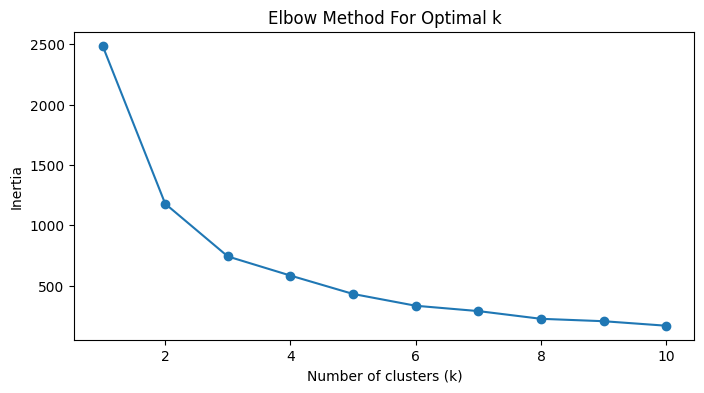

cluster
2    39139
0    37916
1     9716
Name: count, dtype: int64


,type,price,bedrooms,bathrooms,area,location,cluster
0,Apartment,3800000,3.0,2.0,150.0,"10th District, Sheikh Zayed, Giza",0
1,Apartment,3400000,3.0,2.0,169.0,"10th District, Sheikh Zayed, Giza",0
2,Apartment,4400000,3.0,2.0,175.0,"10th District, Sheikh Zayed, Giza",0
3,Apartment,4400000,3.0,2.0,175.0,"10th District, Sheikh Zayed, Giza",0
4,Apartment,5500000,3.0,2.0,180.0,"10th District, Sheikh Zayed, Giza",0


In [104]:
# KMeans clustering on price, area, bedrooms, bathrooms
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt

# Select features for clustering
features = ['price', 'area', 'bedrooms', 'bathrooms']
X = df_final[features]

# Standardize the features
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# Find optimal number of clusters using the elbow method
inertia = []
K_range = range(1, 11)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K_range, inertia, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method For Optimal k')
plt.show()

# Choose k (for example, 3) based on the elbow plot
k = 3
kmeans = KMeans(n_clusters=k, random_state=42)
df_final['cluster'] = kmeans.fit_predict(X_scaled)

# Show the number of samples in each cluster
print(df_final['cluster'].value_counts())

# Show a sample of the clustered data
df_final.head()

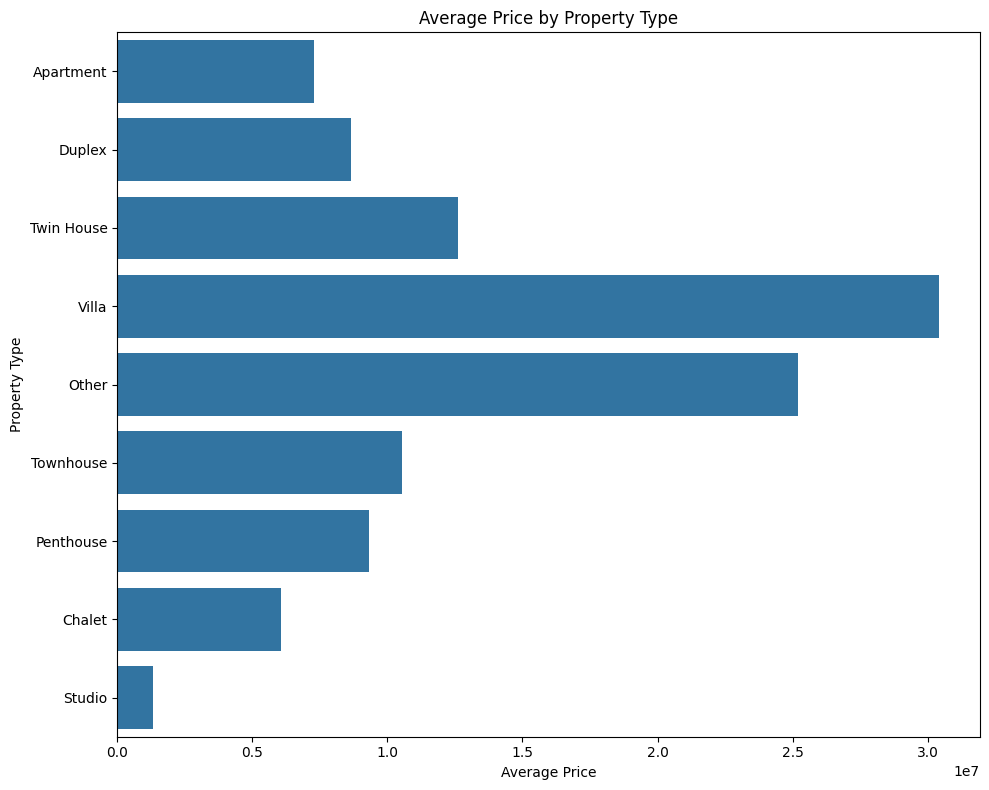

In [105]:
# Horizontal bar plot: Average price by property type
plt.figure(figsize=(10, 8))
sns.barplot(y='type', x='price', data=df_final, estimator= np.mean, errorbar=None)
plt.title('Average Price by Property Type')
plt.xlabel('Average Price')
plt.ylabel('Property Type')
plt.tight_layout()
plt.show()

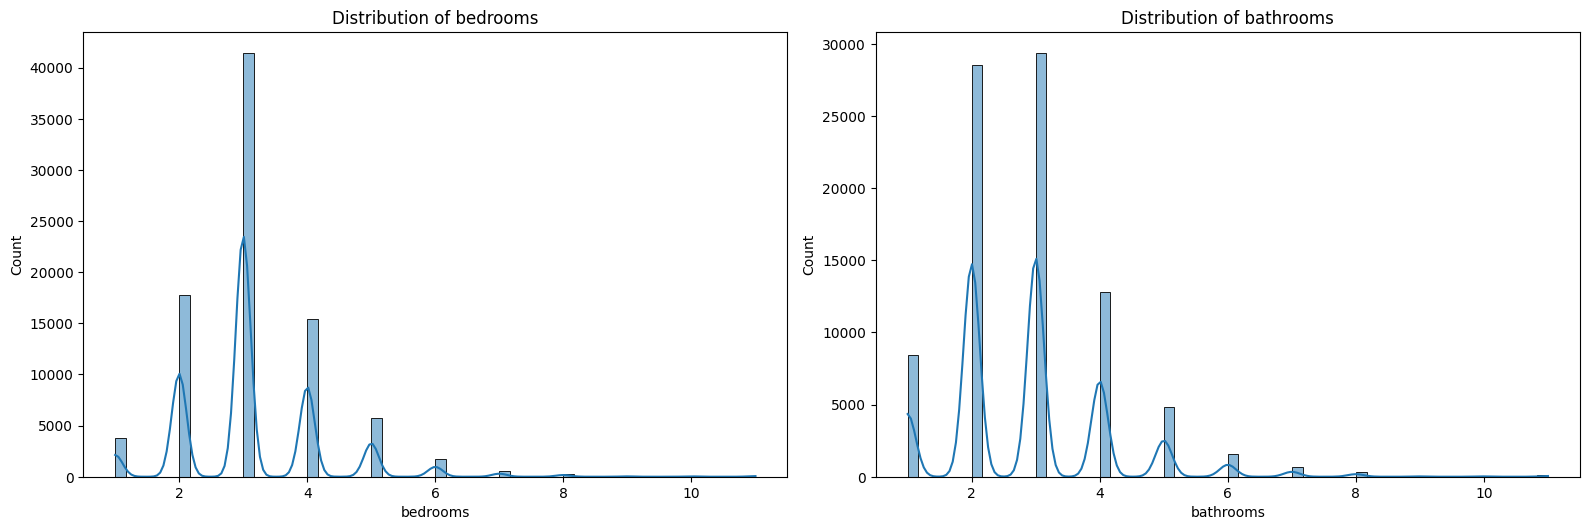

In [106]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_cols = ['bedrooms', 'bathrooms']
plt.figure(figsize=(16, 10))
for i, col in enumerate(numerical_cols, 1):
    plt.subplot(2, 2, i)
    sns.histplot(df_final[col].dropna(), kde=True, bins=60)
    plt.title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

In [107]:
numerical_cols = ['bedrooms', 'bathrooms', 'area', 'price']

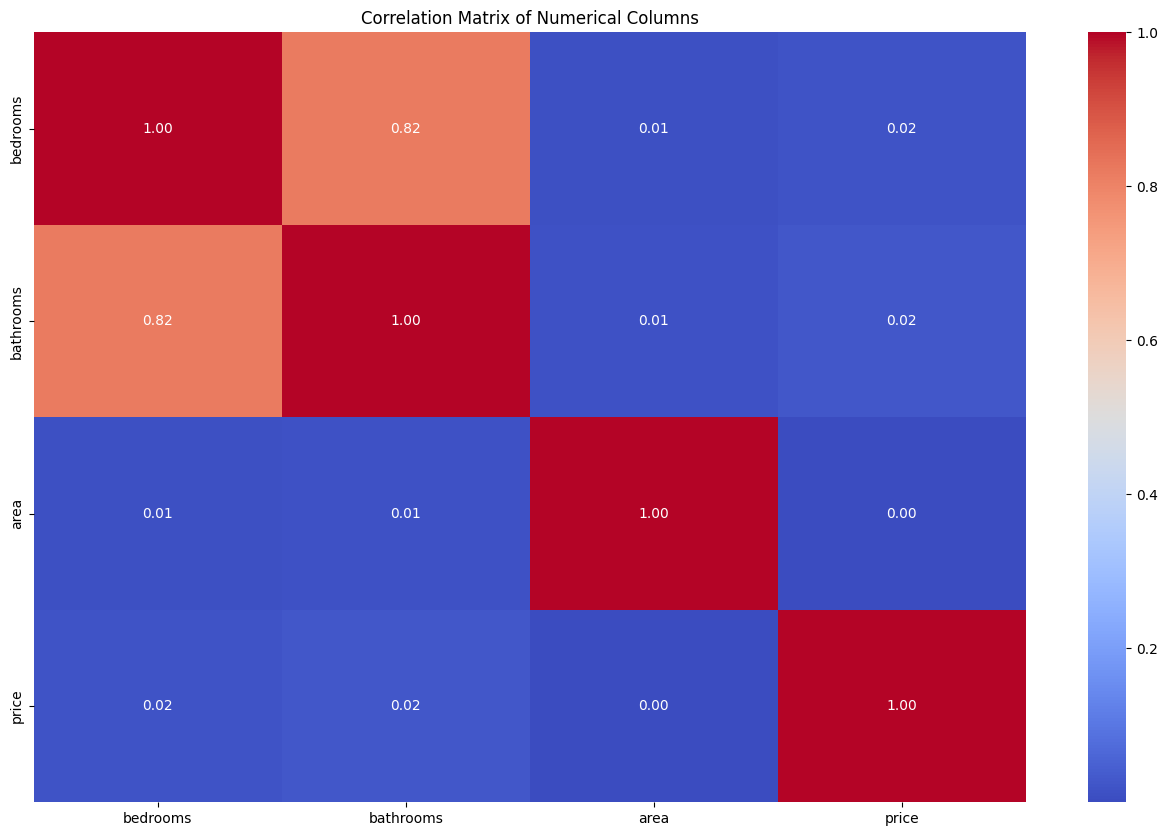

In [108]:
plt.figure(figsize=(16, 10))
sns.heatmap(df_final[numerical_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numerical Columns')
plt.show()

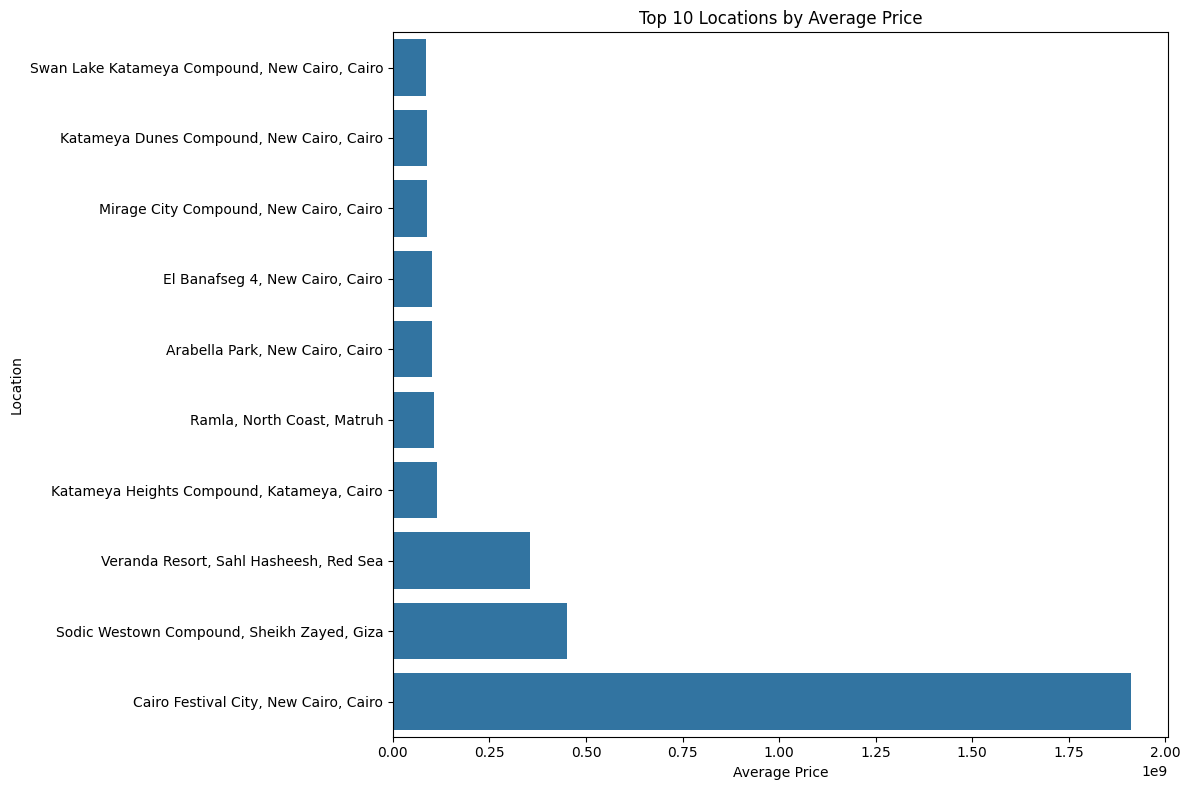

In [109]:
# Horizontal bar plot: Top 10 locations by average price
top_locations = df_final.groupby('location')['price'].mean().sort_values(ascending=True).tail(10)
plt.figure(figsize=(12, 8))
sns.barplot(y=top_locations.index, x=top_locations.values)
plt.title('Top 10 Locations by Average Price')
plt.xlabel('Average Price')
plt.ylabel('Location')
plt.tight_layout()
plt.show()

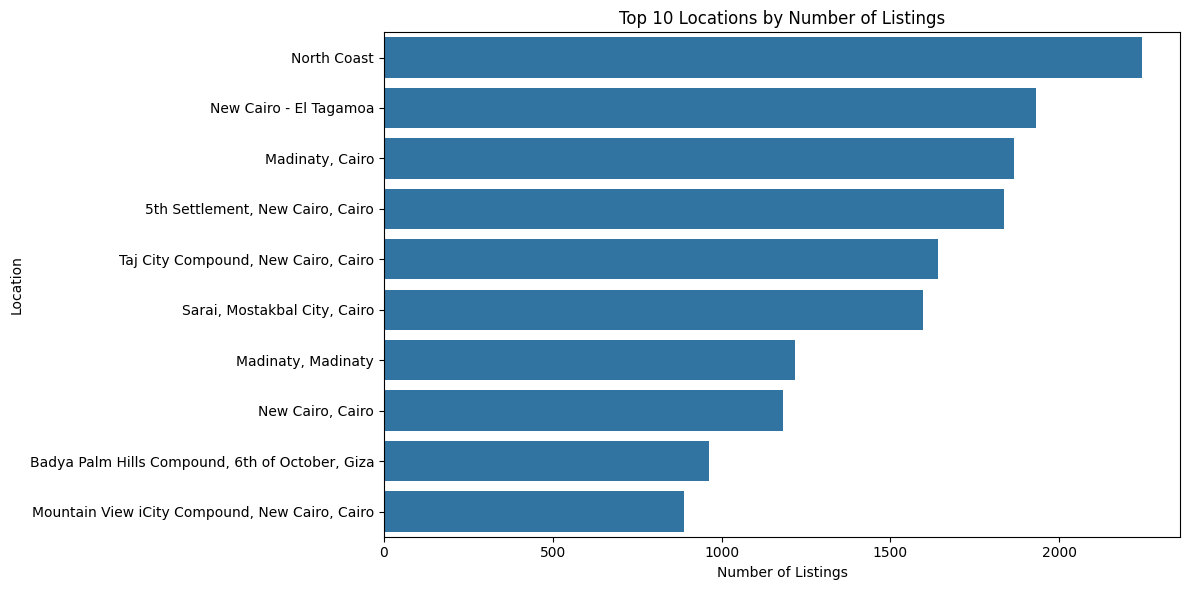

In [110]:
# Bar plot: Top 10 locations by count of listings (Horizontal)
top_locations_count = df_final['location'].value_counts().head(10)
plt.figure(figsize=(12, 6))
sns.barplot(x=top_locations_count.values, y=top_locations_count.index)
plt.title('Top 10 Locations by Number of Listings')
plt.xlabel('Number of Listings')
plt.ylabel('Location')
plt.tight_layout()
plt.show()

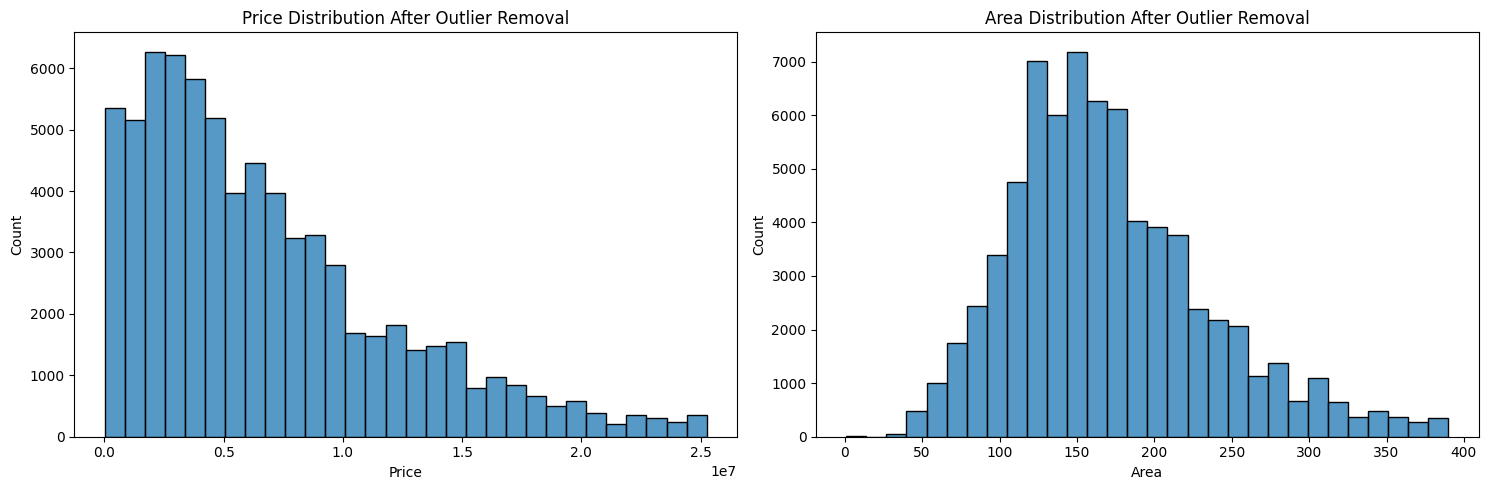

In [111]:
# Visualize distributions after outlier removal
plt.figure(figsize=(15, 5))

# Price distribution
plt.subplot(1, 2, 1)
sns.histplot(data=df_final_clean, x='price', bins=30)
plt.title('Price Distribution After Outlier Removal')
plt.xlabel('Price')

# Area distribution
plt.subplot(1, 2, 2)
sns.histplot(data=df_final_clean, x='area', bins=30)
plt.title('Area Distribution After Outlier Removal')
plt.xlabel('Area')

plt.tight_layout()
plt.show()

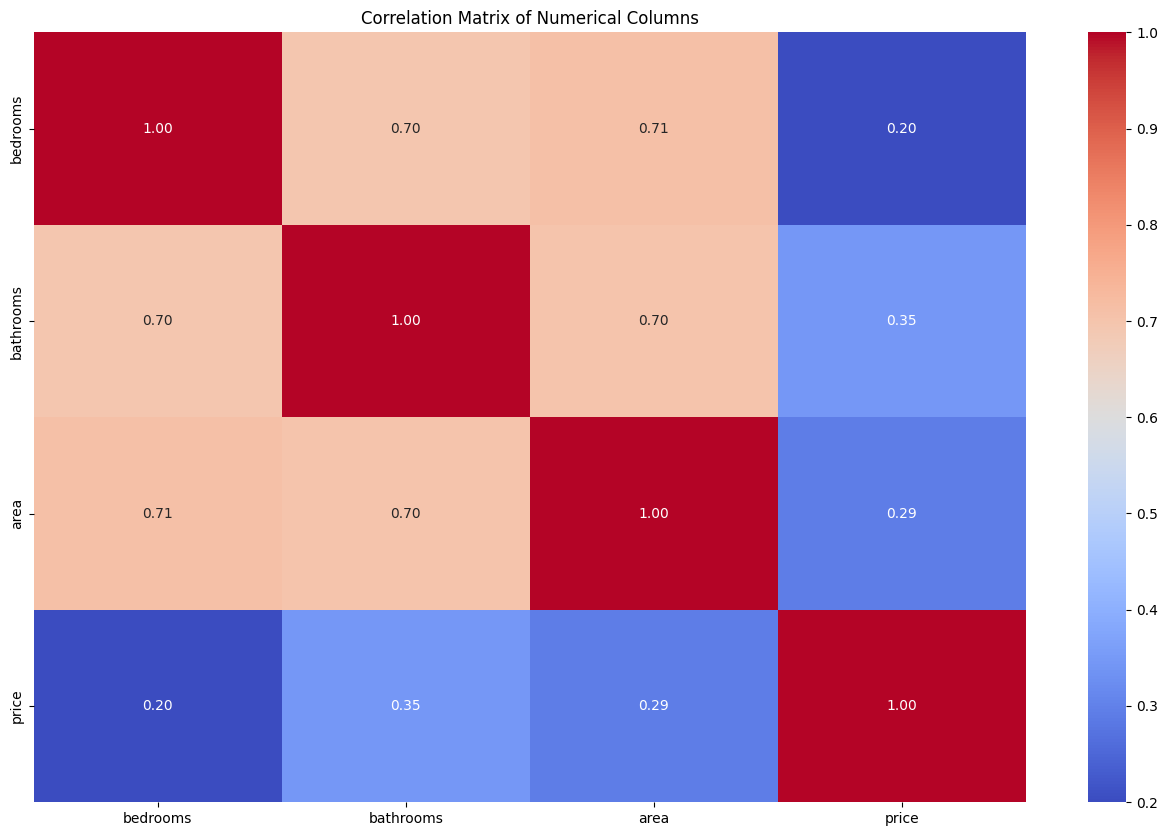

In [112]:
plt.figure(figsize=(16, 10))
sns.heatmap(df_final_clean[numerical_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numerical Columns')
plt.show()

# 4. Modeling
## 4.1 Feature Engineering and Data Preparation

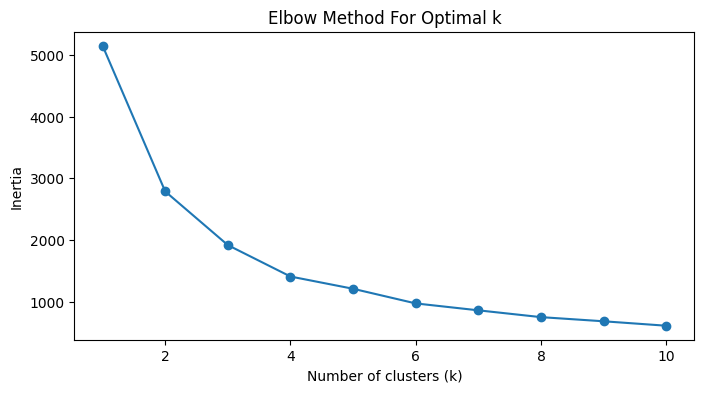

cluster
2    40408
1    15801
0    15303
Name: count, dtype: int64


,type,price,bedrooms,bathrooms,area,location,cluster
0,Apartment,3800000,3.0,2.0,150.0,"10th District, Sheikh Zayed, Giza",2
1,Apartment,3400000,3.0,2.0,169.0,"10th District, Sheikh Zayed, Giza",2
2,Apartment,4400000,3.0,2.0,175.0,"10th District, Sheikh Zayed, Giza",2
3,Apartment,4400000,3.0,2.0,175.0,"10th District, Sheikh Zayed, Giza",2
4,Apartment,5500000,3.0,2.0,180.0,"10th District, Sheikh Zayed, Giza",2


In [113]:
# KMeans clustering on price, area, bedrooms, bathrooms
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt

# Select features for clustering
features = ['price', 'area']
X = df_final_clean[features]

# Standardize the features
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# Find optimal number of clusters using the elbow method
inertia = []
K_range = range(1, 11)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K_range, inertia, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method For Optimal k')
plt.show()

# Choose k (for example, 3) based on the elbow plot
k = 3
kmeans = KMeans(n_clusters=k, random_state=42)
df_final_clean['cluster'] = kmeans.fit_predict(X_scaled)

# Show the number of samples in each cluster
print(df_final_clean['cluster'].value_counts())

# Show a sample of the clustered data
df_final_clean.head()

# 4. Modeling
## 4.1 Feature Engineering and Data Preparation

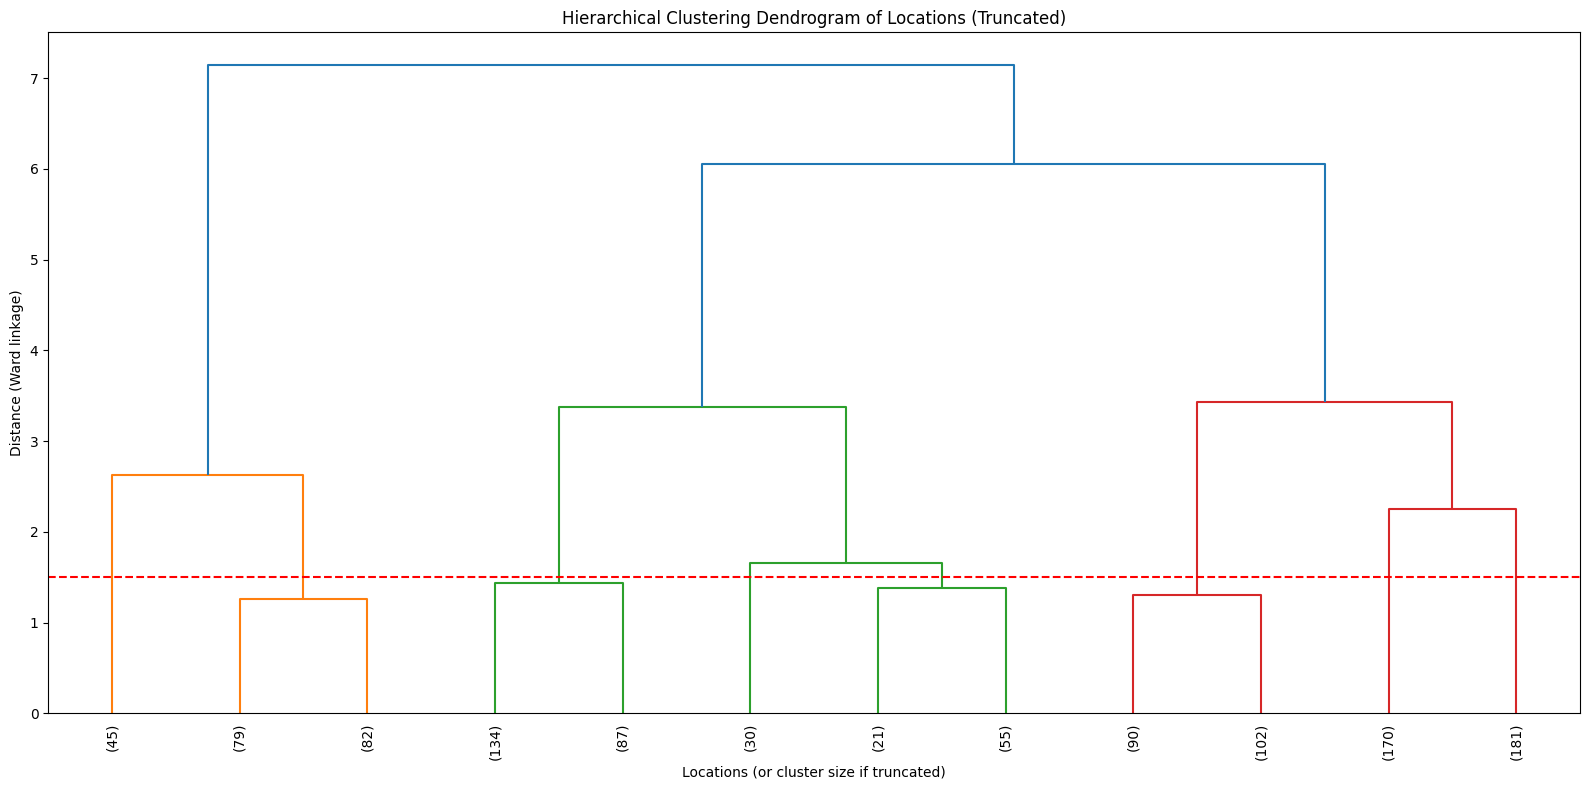


--- Analysis of Location Clusters and Entropy ---

** Analyzing for 3 clusters **
Overall Entropy for 3 clusters: 1.4767
  Cluster 0 (Avg Price: $3879226.29, Avg Area: 146.12 sq m)
    Number of unique locations: 543
  Cluster 1 (Avg Price: $12606111.00, Avg Area: 167.64 sq m)
    Number of unique locations: 206
  Cluster 2 (Avg Price: $6070732.42, Avg Area: 229.64 sq m)
    Number of unique locations: 327


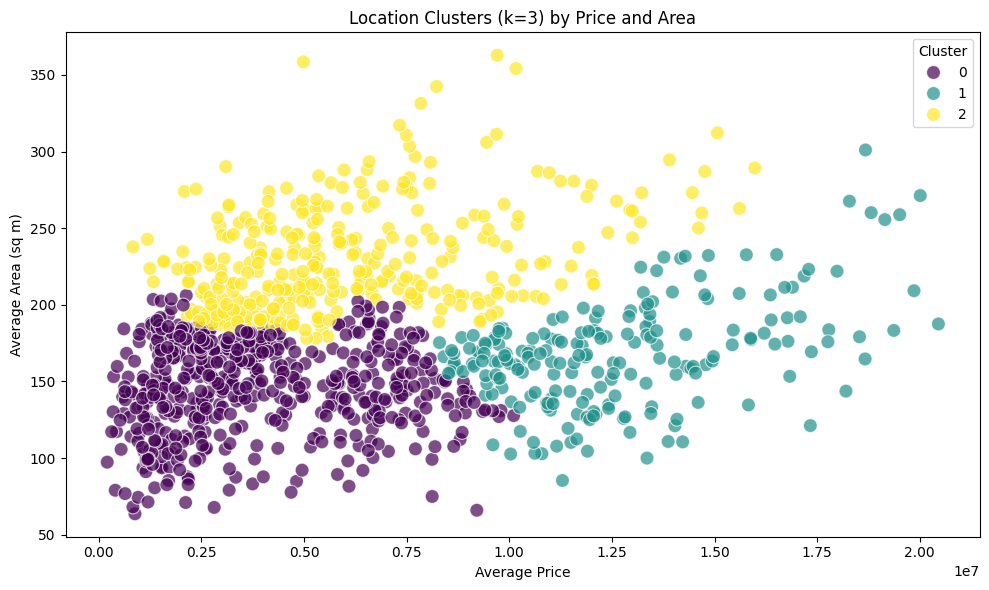

In [114]:

# Hierarchical clustering dendrogram, location analysis, and entropy calculation
import scipy.cluster.hierarchy as sch
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import AgglomerativeClustering
import numpy as np

# Group by location and compute mean price and area
location_features = df_final_clean.groupby('location')[['price', 'area']].mean().reset_index()

# Filter out locations with very few listings (optional, e.g., > 5 listings)
location_counts = df_final_clean['location'].value_counts()
common_locations = location_counts[location_counts > 5].index.tolist()
location_features = location_features[location_features['location'].isin(common_locations)]

# Set location as index for use in dendrogram labels
location_features_indexed = location_features.set_index('location')

# MinMax scale the features for clustering
scaler = MinMaxScaler()
location_scaled = scaler.fit_transform(location_features_indexed[['price', 'area']])

# Compute linkage matrix for hierarchical clustering
linkage_matrix = sch.linkage(location_scaled, method='ward')

# Plot dendrogram
plt.figure(figsize=(16, 8))
dendro = sch.dendrogram(linkage_matrix,
                        labels=location_features_indexed.index,
                        leaf_rotation=90,
                        truncate_mode='lastp',  # Show only the last p merged clusters
                        p=12,  # Number of clusters to show at the bottom (can be adjusted)
                        show_leaf_counts=True,
                        leaf_font_size=10)
plt.title('Hierarchical Clustering Dendrogram of Locations (Truncated)')
plt.xlabel('Locations (or cluster size if truncated)')
plt.ylabel('Distance (Ward linkage)')
plt.axhline(y=1.5, color='r', linestyle='--')  # Example threshold, adjust based on dendrogram
plt.tight_layout()
plt.show()

# Function to calculate entropy
def calculate_entropy(labels):
    value_counts = pd.Series(labels).value_counts(normalize=True, sort=False)
    return -np.sum(value_counts * np.log2(value_counts + 1e-9))  # Small epsilon to avoid log(0)

# ...end of existing code...

# *** CHANGED CODE BELOW: use only 3 clusters, do not iterate ***
num_clusters = 3
hc = AgglomerativeClustering(n_clusters=num_clusters, linkage='ward')
location_features['cluster_label'] = hc.fit_predict(location_scaled)

print("\n--- Analysis of Location Clusters and Entropy ---")
print(f"\n** Analyzing for {num_clusters} clusters **")

overall_entropy = calculate_entropy(location_features['cluster_label'])
print(f"Overall Entropy for {num_clusters} clusters: {overall_entropy:.4f}")

for i in range(num_clusters):
    cluster_data = location_features[location_features['cluster_label'] == i]
    locations_in_cluster = cluster_data['location'].tolist()
    avg_price = cluster_data['price'].mean()
    avg_area = cluster_data['area'].mean()
    unique_locations_count = cluster_data['location'].nunique()

    print(f"  Cluster {i} (Avg Price: ${avg_price:.2f}, Avg Area: {avg_area:.2f} sq m)")
    print(f"    Number of unique locations: {unique_locations_count}")

# Single scatter plot for 3 clusters
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=location_features,
    x='price',
    y='area',
    hue='cluster_label',
    palette='viridis',
    s=100, alpha=0.7
)
plt.title(f'Location Clusters (k={num_clusters}) by Price and Area')
plt.xlabel('Average Price')
plt.ylabel('Average Area (sq m)')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

<Axes: title={'center': 'price'}, xlabel='type'>

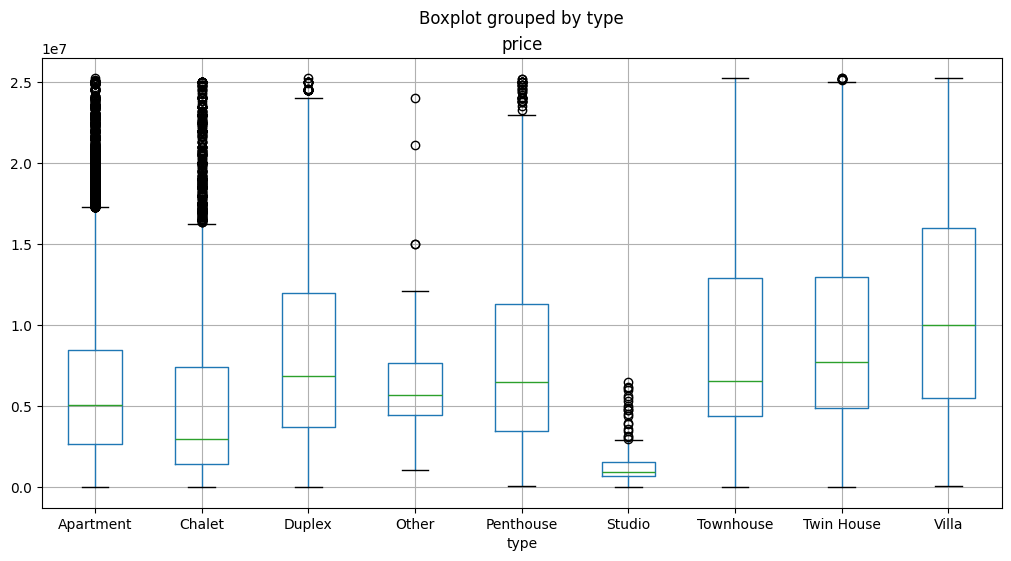

In [115]:
df_final_clean.boxplot(column='price', by='type', figsize=(12, 6))

In [116]:
# Function to remove outliers by property type
def remove_outliers_by_type(df, columns, property_types):
    df_clean = df.copy()

    for property_type in property_types:
        type_data = df_clean[df_clean['type'] == property_type]
        if len(type_data) == 0:
            continue

        print(f"\nProcessing {property_type}:")
        print(f"Original count: {len(type_data)}")

        for col in columns:
            Q1 = type_data[col].quantile(0.25)
            Q3 = type_data[col].quantile(0.75)
            IQR = Q3 - Q1
            lower_bound = Q1 - 1.5 * IQR
            upper_bound = Q3 + 1.5 * IQR

            # Create mask for this property type and column
            mask = df_clean['type'] == property_type
            mask &= df_clean[col].between(lower_bound, upper_bound)

            # Update df_clean to keep only non-outlier values for this type and column
            df_clean = df_clean[~(df_clean['type'] == property_type) | mask]

            print(f"{col} - Removed outliers < {lower_bound:.2f} or > {upper_bound:.2f}")

        print(f"Remaining count: {len(df_clean[df_clean['type'] == property_type])}")

    return df_clean

# Get valid property types (those with sufficient data)
valid_types = df_final_clean['type'].value_counts()[df_final_clean['type'].value_counts() > 10].index.tolist()

# Remove outliers for each property type
numerical_cols = ['price', 'area', 'bedrooms', 'bathrooms']
print("Original total shape:", df_final_clean.shape)
df_final_clean_by_type = remove_outliers_by_type(df_final_clean, numerical_cols, valid_types)
print("\nFinal shape after removing outliers by type:", df_final_clean_by_type.shape)


# Display summary statistics for each type
print("\nSummary statistics by property type:")
for prop_type in valid_types:
    print(f"\n{prop_type}:")
    print(df_final_clean_by_type[df_final_clean_by_type['type'] == prop_type]['price'].describe())

Original total shape: (71512, 7)

Processing Apartment:
Original count: 41017
price - Removed outliers < -6125000.00 or > 17275000.00
area - Removed outliers < 47.50 or > 259.50
bedrooms - Removed outliers < 0.50 or > 4.50
bathrooms - Removed outliers < 0.50 or > 4.50
Remaining count: 38892

Processing Chalet:
Original count: 11367
price - Removed outliers < -7475000.00 or > 16325000.00
area - Removed outliers < 30.50 or > 202.50
bedrooms - Removed outliers < 0.50 or > 4.50
bathrooms - Removed outliers < 2.00 or > 2.00
Remaining count: 6803

Processing Villa:
Original count: 6000
price - Removed outliers < -10250000.00 or > 31750000.00
area - Removed outliers < 72.50 or > 412.50
bedrooms - Removed outliers < 1.50 or > 5.50
bathrooms - Removed outliers < 1.50 or > 5.50
Remaining count: 5958

Processing Townhouse:
Original count: 5437
price - Removed outliers < -8332500.00 or > 25639500.00
area - Removed outliers < 83.00 or > 363.00
bedrooms - Removed outliers < 1.50 or > 5.50
bathrooms 

In [117]:
# Import required libraries
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Check for GPU availability
print("GPU Available: ", tf.config.list_physical_devices('GPU'))
print("TensorFlow version:", tf.__version__)

# Force TensorFlow to use GPU
gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("GPU memory growth enabled")
    except RuntimeError as e:
        print(e)



GPU Available:  [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
TensorFlow version: 2.18.0
GPU memory growth enabled


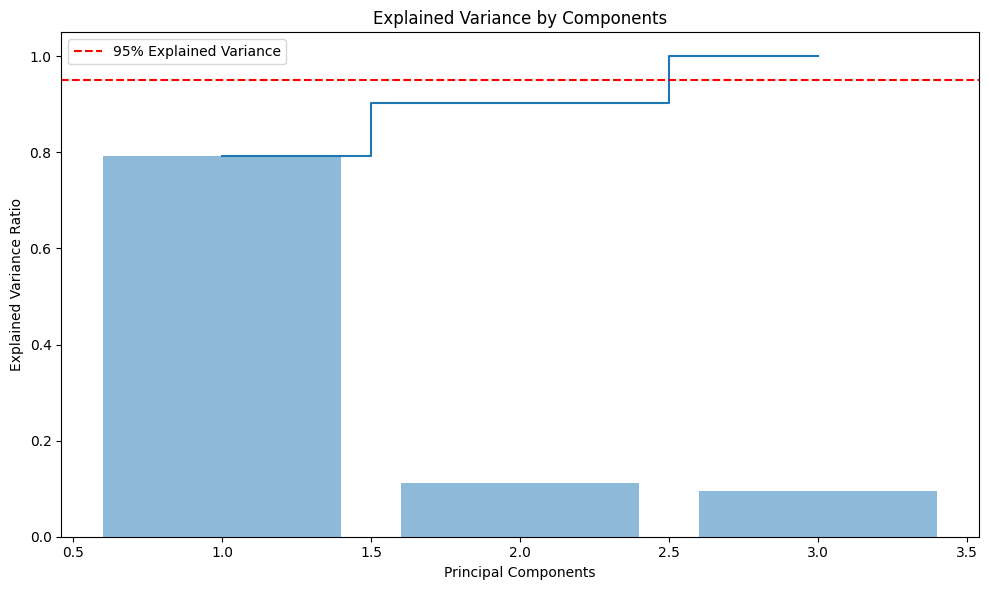

In [118]:
# Import required libraries for PCA
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.regularizers import l2

# Prepare the data for modeling
data = df_final_clean_by_type.copy()

# Remove any remaining NaNs
data = data.dropna()

# Get target variable
y = data['price'].values

# Define feature columns
categorical_cols = ['type', 'location']
numerical_cols = ['bedrooms', 'bathrooms', 'area']

# First, let's separately process numerical and categorical features
# Standardize numerical features
scaler = StandardScaler()
X_numerical = scaler.fit_transform(data[numerical_cols])

# One-hot encode categorical features
encoder = OneHotEncoder(handle_unknown='ignore')
X_categorical = encoder.fit_transform(data[categorical_cols]).toarray()

# Perform PCA on numerical features and analyze variance
pca = PCA()
X_pca = pca.fit_transform(X_numerical)

# Plot the explained variance ratio
plt.figure(figsize=(10, 6))
plt.bar(range(1, len(pca.explained_variance_ratio_) + 1), pca.explained_variance_ratio_, alpha=0.5, align='center')
plt.step(range(1, len(pca.explained_variance_ratio_) + 1), np.cumsum(pca.explained_variance_ratio_), where='mid')
plt.ylabel('Explained Variance Ratio')
plt.xlabel('Principal Components')
plt.title('Explained Variance by Components')
plt.axhline(y=0.95, color='r', linestyle='--', label='95% Explained Variance')
plt.legend()
plt.tight_layout()
plt.show()



/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 32)             │        83,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 83,393 (325.75 KB)

 Trainable params: 83,393 (325.75 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
1265/1265 - 7s - 6ms/step - loss: 44.0581 - mean_absolute_error: 4.6733 - val_loss: 0.8159 - val_mean_absolute_error: 0.6938
Epoch 2/50
1265/1265 - 4s - 3ms/step - loss: 4.1711 - mean_absolute_error: 1.6180 - val_loss: 0.4928 - val_mean_absolute_error: 0.5364
Epoch 3/50
1265/1265 - 4s - 3ms/step - loss: 3.8211 - mean_absolute_error: 1.5549 - val_loss: 0.4794 - val_mean_absolute_error: 0.5377
Epoch 4/50
1265/1265 - 5s - 4ms/step - loss: 3.6250 - mean_absolute_error: 1.5136 - val_loss: 0.4627 - val_mean_absolute_error: 0.5402
Epoch 5/50
1265/1265 - 5s - 4ms/step - loss: 3.4861 - mean_absolute_error: 1.4783 - val_loss: 0.4160 - val_mean_absolute_error: 0.4833
Epoch 6/50
1265/1265 - 4s - 3ms/step - loss: 3.2169 - mean_absolute_error: 1.4238 - val_loss: 0.4328 - val_mean_absolute_error: 0.5142
Epoch 7/50
1265/1265 - 5s - 4ms/step - loss: 2.9182 - mean_absolute_error: 1.3547 - val_loss: 0.3926 - val_mean_absolute_error: 0.4595
Epoch 8/50
1265/1265 - 3s - 3ms/step - loss: 2.6361 - 

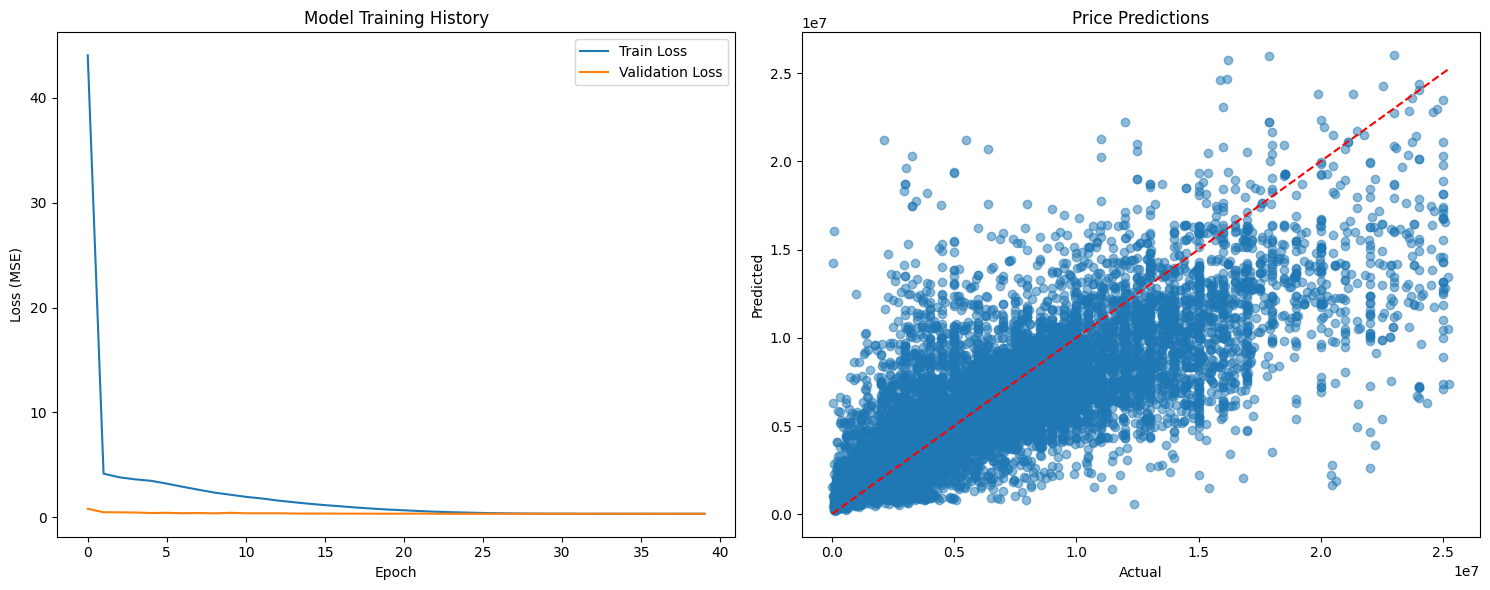

In [119]:
# Simplified TensorFlow model for real estate price prediction
import tensorflow as tf
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
from tensorflow.keras.callbacks import EarlyStopping

# Assuming data preparation code is already executed above to get X_numerical and X_categorical

# Create PCA with 2 components - keeping this simple
pca = PCA(n_components=2)
X_numerical_pca = pca.fit_transform(X_numerical)

# Combine transformed features
X_combined = np.hstack((X_numerical_pca, X_categorical))

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X_combined, y, test_size=0.2, random_state=42)

# Log transform the target variable
y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

# Build a simpler TensorFlow model
model = tf.keras.Sequential([
    tf.keras.layers.Dense(32, activation='relu', input_shape=(X_train.shape[1],)),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(1)
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='mean_squared_error',
    metrics=['mean_absolute_error']
)

# Simple summary of model architecture
model.summary()

# Set up early stopping only (simplifying callbacks)
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True
)

# Train the model with verbose=2 for clearer epoch-by-epoch progress
history = model.fit(
    X_train, y_train_log,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=2  # Show one line per epoch (clearer than progress bar)
)

# Evaluate the model
y_pred_log = model.predict(X_test, verbose=0)  # Silent prediction
y_pred = np.expm1(y_pred_log)

# Calculate metrics
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"\nModel Performance:")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared (R²): {r2:.4f}")

# Plot results in a simple figure
plt.figure(figsize=(15, 6))

# Plot 1: Training history
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Training History')
plt.ylabel('Loss (MSE)')
plt.xlabel('Epoch')
plt.legend()

# Plot 2: Predictions vs Actual
plt.subplot(1, 2, 2)
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.title('Price Predictions')
plt.xlabel('Actual')
plt.ylabel('Predicted')

plt.tight_layout()
plt.show()

Classification Report:
              precision    recall  f1-score   support

   Apartment       0.76      0.79      0.78      1721
      Chalet       0.78      0.78      0.78      1317
      Duplex       0.38      0.29      0.33       185
   Penthouse       0.25      0.15      0.19        99
      Studio       0.41      0.35      0.38        49
   Townhouse       0.51      0.57      0.54       558
  Twin House       0.53      0.46      0.49       481
       Villa       0.75      0.77      0.76       919

    accuracy                           0.70      5329
   macro avg       0.55      0.52      0.53      5329
weighted avg       0.69      0.70      0.69      5329



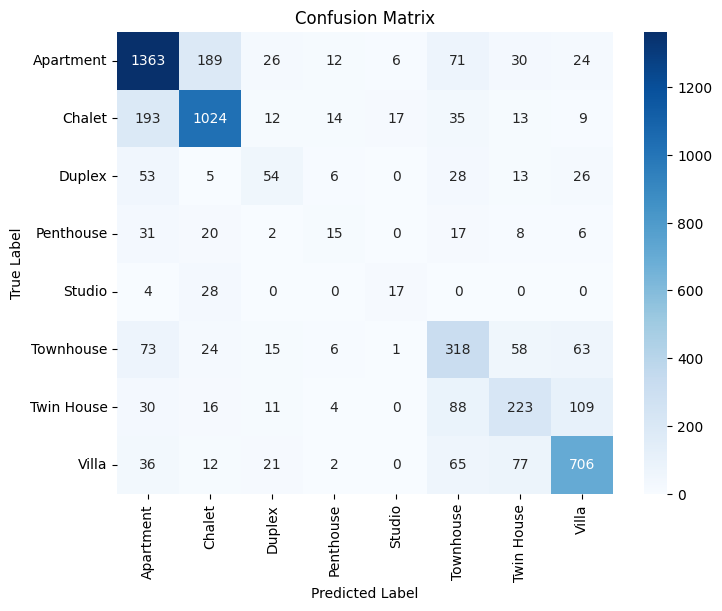

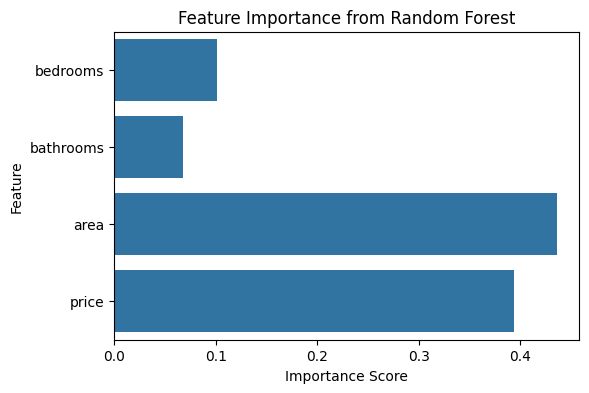

In [120]:

# Classification - Random Forest
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

# Example: Predicting property 'type' using other features
df_class = df1.dropna(subset=['type', 'bedrooms', 'bathrooms', 'area', 'price'])
X = df_class[['bedrooms', 'bathrooms', 'area', 'price']]

y = df_class['type']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

clf = RandomForestClassifier()
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

print("Classification Report:")
print(classification_report(y_test, y_pred))
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=clf.classes_, yticklabels=clf.classes_, cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

importances = clf.feature_importances_
feature_names = X.columns

plt.figure(figsize=(6, 4))
sns.barplot(x=importances, y=feature_names)
plt.title("Feature Importance from Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.show()



In [121]:

# Apriori - Association Rule Mining
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

# Example: convert dataset into list of transactions
transactions = df1.dropna(subset=['type', 'location'])[['type', 'location']].values.tolist()
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df_apriori = pd.DataFrame(te_ary, columns=te.columns_)

frequent_itemsets = apriori(df_apriori, min_support=0.01, use_colnames=True)
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1.0)

print("Apriori Rules:")
print(rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']])


Apriori Rules:
                                 antecedents  \
0                           (6th of October)   
1                                (Apartment)   
2                               (Ain Sukhna)   
3                                   (Chalet)   
4                                (Apartment)   
5                       (Madinaty, Madinaty)   
6                   (New Cairo - El Tagamoa)   
7                                (Apartment)   
8                             (Sheikh Zayed)   
9                                (Apartment)   
10                             (North Coast)   
11                                  (Chalet)   
12  (North Coast, Mountain View North Coast)   
13                                  (Chalet)   
14                                   (Villa)   
15                      (Madinaty, Madinaty)   
16                  (New Cairo - El Tagamoa)   
17                                   (Villa)   
18                               (Townhouse)   
19                       

In [122]:
# Step 1: Create price range bins
df_ap = df1.dropna(subset=['type', 'location', 'price']).copy()
df_ap['price_range'] = pd.qcut(df_ap['price'], q=3, labels=['Low', 'Medium', 'High'])

# Step 2: Convert rows to transactions (lists of strings)
transactions = df_ap[['type', 'location', 'price_range']].values.tolist()

# Step 3: Apply Transaction Encoder
from mlxtend.preprocessing import TransactionEncoder
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df_encoded = pd.DataFrame(te_ary, columns=te.columns_)

# Step 4: Apply Apriori
from mlxtend.frequent_patterns import apriori, association_rules
frequent_itemsets = apriori(df_encoded, min_support=0.01, use_colnames=True)

rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1.0)

# Step 5: Display interesting rules
rules_filtered = rules[
    (rules['consequents'].astype(str).str.contains('High|Medium|Low')) &
    (rules['lift'] > 1)
]

print("Association Rules including Price Range:")
print(rules_filtered[['antecedents', 'consequents', 'support', 'confidence', 'lift']])


Association Rules including Price Range:
                                          antecedents  \
2                                    (6th of October)   
6                                        (Ain Sukhna)   
8                                         (Apartment)   
13                                        (Apartment)   
18                                           (Chalet)   
21                                           (Chalet)   
26                                           (Duplex)   
29                               (Madinaty, Madinaty)   
30      (New Cairo - El Tagamoa, Hyde Park New Cairo)   
32                   (New Cairo - El Tagamoa, Mivida)   
34                             (North Coast, Marassi)   
37                                     (Sheikh Zayed)   
38                                        (Townhouse)   
40                                       (Twin House)   
43                                            (Villa)   
44                           (New Cairo - El Ta

<ipython-input-123-054c79ad3b42>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  rules_filtered['antecedents_str'] = rules_filtered['antecedents'].apply(lambda x: ', '.join(list(x)))
<ipython-input-123-054c79ad3b42>:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  rules_filtered['consequents_str'] = rules_filtered['consequents'].apply(lambda x: ', '.join(list(x)))
<ipython-input-123-054c79ad3b42>:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[r

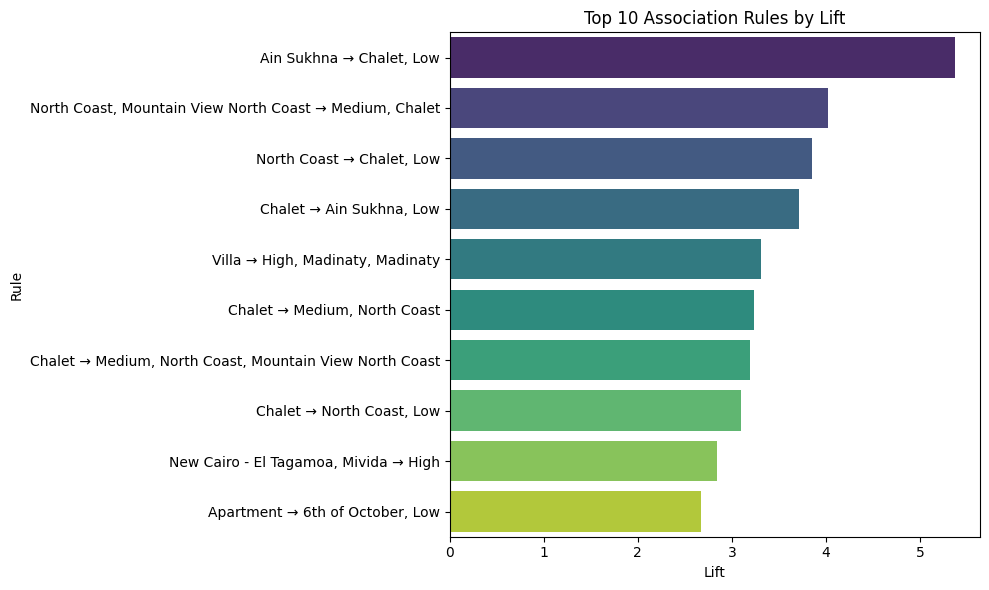

In [123]:
import matplotlib.pyplot as plt
import seaborn as sns

# Convert frozensets to strings for easier plotting
rules_filtered['antecedents_str'] = rules_filtered['antecedents'].apply(lambda x: ', '.join(list(x)))
rules_filtered['consequents_str'] = rules_filtered['consequents'].apply(lambda x: ', '.join(list(x)))
rules_filtered['rule'] = rules_filtered['antecedents_str'] + ' → ' + rules_filtered['consequents_str']

# Sort and select top 10 rules by lift
top_rules = rules_filtered.sort_values(by='lift', ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(data=top_rules, y='rule', x='lift', palette='viridis')
plt.title('Top 10 Association Rules by Lift')
plt.xlabel('Lift')
plt.ylabel('Rule')
plt.tight_layout()
plt.show()


In [124]:

# Regression - Linear Regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Predicting price from features
df_reg = df1.dropna(subset=['bedrooms', 'bathrooms', 'area', 'price'])
X = df_reg[['bedrooms', 'bathrooms', 'area']]

y = df_reg['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

reg = LinearRegression()
reg.fit(X_train, y_train)
y_pred = reg.predict(X_test)

print("Regression Results:")
print(f"Mean Squared Error: {mean_squared_error(y_test, y_pred):.2f}")
print(f"R^2 Score: {r2_score(y_test, y_pred):.2f}")


Regression Results:
Mean Squared Error: 22019025164703.05
R^2 Score: 0.37
